# 14 — Comparação com outras cidades, IDH, pacientes de fora e quem atende Ilhéus

**Análises do plano:** A8 (raio de atendimento: pacientes de fora e quem atende os moradores de Ilhéus),
A9 (comparação com as 10 cidades e litoral x interior), A10 (IDH e densidade x incidência na Bahia) e
A11 (comparação com números publicados). Atende o item da reunião "normalizar por 100 mil habitantes as
comparações com as capitais".

**Definições**

- Todas as taxas são de **casos novos por residência**, por 100 mil habitantes, com a população anual do
  notebook 09. A taxa média do período é a soma dos casos dividida pela soma das populações de 2014 a 2024.
- Desfechos: coorte de casos novos sem mudança de diagnóstico, excluindo os ainda sem encerramento.
- Litoral x interior entre as 10 cidades: litoral = Ilhéus, Salvador, Recife, Aracaju, Rio de Janeiro;
  interior = Itabuna, Vitória da Conquista, Feira de Santana, São Paulo, Curitiba.

In [1]:
import sys
import json
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import geopandas as gpd
import tb_utils as tb

tb.estilo()
df = tb.carrega_base()
pop = tb.carrega_populacao()
ind = pd.read_csv(tb.EXTERNAL / 'indicadores_municipios.csv', dtype={'cod6': str})
agreg = pd.read_csv(tb.PROCESSED / 'tb_brasil_agregado.csv.gz', dtype={'SG_UF': str, 'ID_MN_RESI': str, 'TRATAMENTO': str})
agreg = agreg[agreg['TRATAMENTO'].eq('1') & agreg['ano_diag'].between(2014, 2024)]
cores = tb.CORES_CIDADE
LITORAL = {'Ilhéus', 'Salvador', 'Recife', 'Aracaju', 'Rio de Janeiro'}
ordem = list(tb.CIDADES.values())

## 1. Incidência por 100 mil nas 10 cidades (A9)

In [2]:
casos_cid = (agreg[agreg['ID_MN_RESI'].isin(tb.CIDADES)]
             .groupby(['ID_MN_RESI', 'ano_diag'])['casos'].sum().rename('casos').reset_index()
             .rename(columns={'ID_MN_RESI': 'cod6', 'ano_diag': 'ano'}))
casos_cid = casos_cid.merge(pop[['cod6', 'ano', 'populacao']], on=['cod6', 'ano'], how='left')
casos_cid['cidade'] = casos_cid['cod6'].map(tb.CIDADES)
casos_cid['taxa'] = casos_cid['casos'] / casos_cid['populacao'] * 1e5

linhas = []
for c, g in casos_cid.groupby('cidade'):
    t, lo, hi = tb.taxa_100k(int(g['casos'].sum()), g['populacao'].sum())
    linhas.append({'cidade': c, 'grupo': 'Litoral' if c in LITORAL else 'Interior', 'casos novos 2014-2024': int(g['casos'].sum()),
                   'taxa média /100 mil': t, 'IC inf': lo, 'IC sup': hi})
taxas10 = pd.DataFrame(linhas).sort_values('taxa média /100 mil', ascending=False).reset_index(drop=True)
taxas10.round(1)

,cidade,grupo,casos novos 2014-2024,taxa média /100 mil,IC inf,IC sup
0,Recife,Litoral,16069,97.3,95.8,98.8
1,Rio de Janeiro,Litoral,65877,96.0,95.3,96.7
2,Itabuna,Interior,1482,70.5,67.0,74.2
3,Salvador,Litoral,16131,59.1,58.2,60.0
4,Ilhéus,Litoral,1161,58.6,55.3,62.1
5,São Paulo,Interior,68503,54.6,54.2,55.0
6,Aracaju,Litoral,2587,39.5,38.0,41.1
7,Feira de Santana,Interior,1895,28.7,27.4,30.0
8,Curitiba,Interior,3547,18.2,17.6,18.8
9,Vitória da Conquista,Interior,677,17.4,16.1,18.7


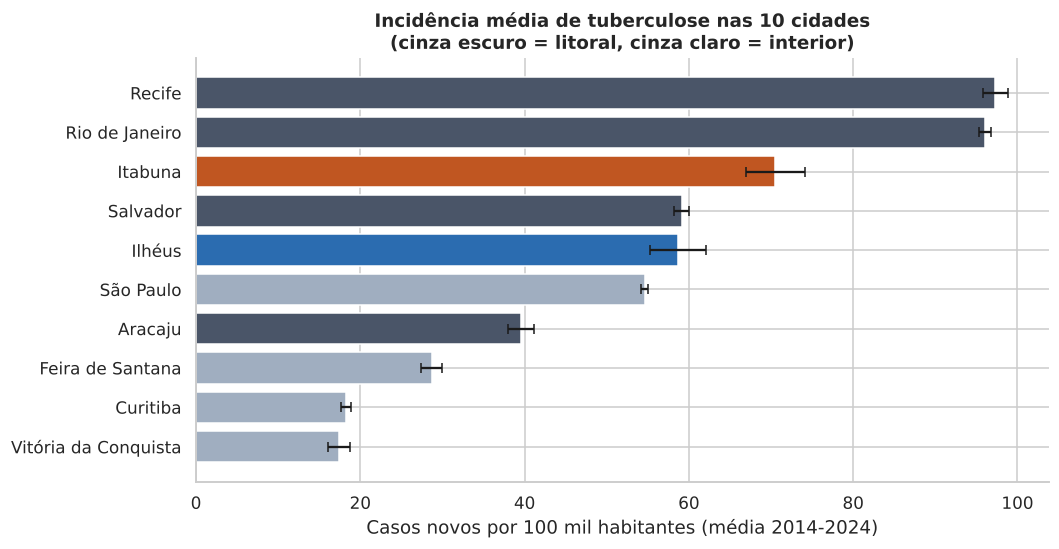

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
cor_barra = [cores.get(c, '#4a5568' if c in LITORAL else '#a0aec0') for c in taxas10['cidade']]
ax.barh(taxas10['cidade'], taxas10['taxa média /100 mil'], color=cor_barra,
        xerr=[taxas10['taxa média /100 mil'] - taxas10['IC inf'], taxas10['IC sup'] - taxas10['taxa média /100 mil']], capsize=3)
ax.invert_yaxis()
ax.set_xlabel('Casos novos por 100 mil habitantes (média 2014-2024)')
ax.set_title('Incidência média de tuberculose nas 10 cidades\n(cinza escuro = litoral, cinza claro = interior)')
tb.salva_fig(fig, '14_incidencia_10_cidades')
plt.show()

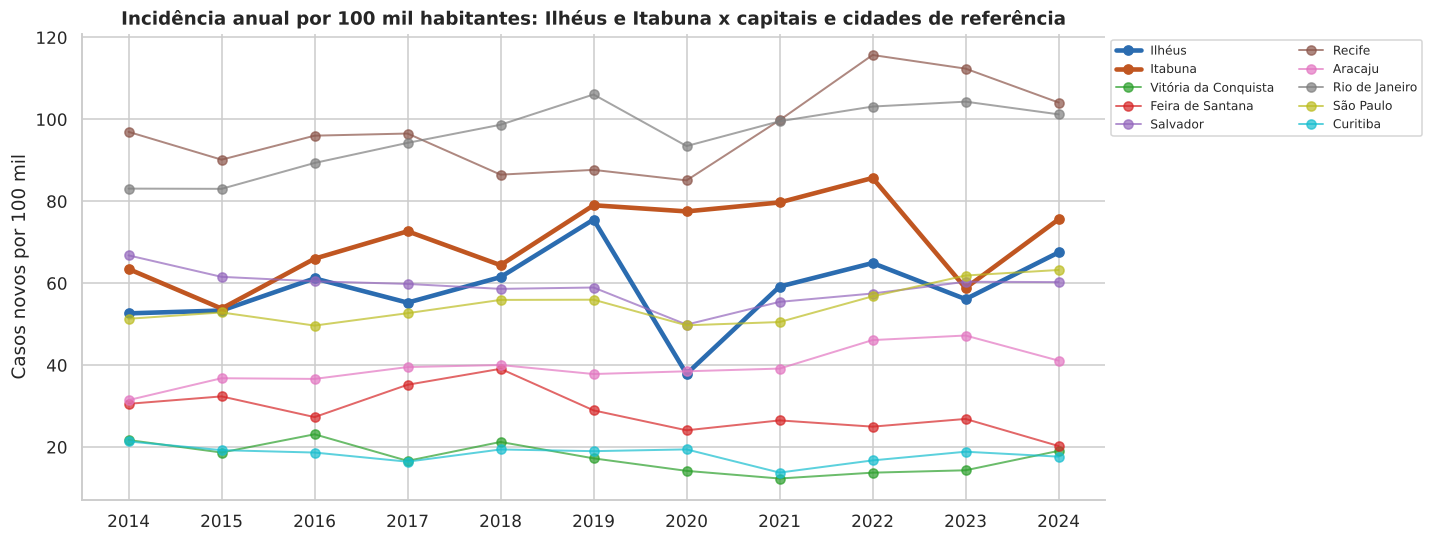

In [4]:
fig, ax = plt.subplots(figsize=(12, 5.5))
pal = sns.color_palette('tab10', len(ordem))
for i, c in enumerate(ordem):
    g = casos_cid[casos_cid['cidade'] == c].sort_values('ano')
    destaque = c in cores
    ax.plot(g['ano'], g['taxa'], marker='o', lw=3 if destaque else 1.3, color=cores.get(c, pal[i]),
            alpha=1 if destaque else 0.7, label=c)
ax.set_xticks(list(tb.ANOS))
ax.set_ylabel('Casos novos por 100 mil')
ax.set_title('Incidência anual por 100 mil habitantes: Ilhéus e Itabuna x capitais e cidades de referência')
ax.legend(ncol=2, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
tb.salva_fig(fig, '14_incidencia_anual_10_cidades')
plt.show()

## 2. Desfechos e indicadores nas 10 cidades

Ilhéus e Itabuna são comparadas, cada uma, com as outras oito cidades somadas (Fisher, Bonferroni).

In [5]:
res10 = df[df['mun_res'].isin(tb.CIDADES) & df['ano_diag'].between(2014, 2024)].copy()
res10['cidade'] = res10['mun_res'].map(tb.CIDADES)
coorte10 = res10[res10['coorte_casos_novos'] & res10['desfecho'].ne('Sem encerramento')]
novos10 = res10[res10['caso_novo']]

def pct(s):
    return 100 * s.mean()

tab10 = pd.DataFrame({
    'coorte (n)': coorte10.groupby('cidade').size(),
    'cura %': coorte10.groupby('cidade')['cura'].apply(pct),
    'abandono %': coorte10.groupby('cidade')['abandono'].apply(pct),
    'óbito TB %': coorte10.groupby('cidade')['obito_tb'].apply(pct),
    'testagem HIV %': novos10.groupby('cidade')['hiv_testado'].apply(pct),
    'HIV+ %': novos10.groupby('cidade')['hiv'].apply(lambda s: 100 * s.eq('Positivo').mean()),
    'pulmonar %': novos10.groupby('cidade')['pulmonar'].apply(pct),
    'alcoolismo %': novos10.groupby('cidade')['alcoolismo'].apply(lambda s: 100 * s.dropna().mean()),
    'situação de rua %': novos10.groupby('cidade')['situacao_rua'].apply(lambda s: 100 * s.dropna().mean()),
    'privado de liberdade %': novos10.groupby('cidade')['privado_liberdade'].apply(lambda s: 100 * s.dropna().mean()),
}).reindex(ordem)
tab10.round(1)

,coorte (n),cura %,abandono %,óbito TB %,testagem HIV %,HIV+ %,pulmonar %,alcoolismo %,situação de rua %,privado de liberdade %
cidade,,,,,,,,,,
Ilhéus,1105,78.8,11.6,2.3,63.1,7.4,89.0,23.8,1.8,3.3
Itabuna,1471,74.5,13.2,5.8,70.3,6.7,82.4,12.7,1.3,17.3
Vitória da Conquista,639,79.8,3.6,6.3,87.4,8.9,76.7,31.4,2.9,2.4
Feira de Santana,1881,79.6,8.3,5.5,72.6,8.7,82.1,17.6,1.3,10.9
Salvador,14891,66.0,12.3,3.1,71.7,9.5,86.0,19.7,2.6,3.7
Recife,15856,65.1,14.7,3.6,73.6,11.7,86.4,21.5,3.6,14.2
Aracaju,2511,69.2,17.4,3.4,76.4,7.0,83.6,21.3,4.7,5.1
Rio de Janeiro,63045,71.5,14.6,3.1,87.5,9.0,89.5,12.6,3.8,14.0
São Paulo,66828,74.5,15.1,3.6,91.7,9.5,83.4,18.9,7.8,3.6


In [6]:
testes = []
for alvo in ['Ilhéus', 'Itabuna']:
    for ind_nome, col in [('cura', 'cura'), ('abandono', 'abandono'), ('óbito por TB', 'obito_tb')]:
        a = coorte10[coorte10['cidade'] == alvo][col]
        o = coorte10[~coorte10['cidade'].isin(['Ilhéus', 'Itabuna'])][col]
        orr, lo, hi, p = tb.fisher_2x2(int(a.sum()), int((1 - a).sum()), int(o.sum()), int((1 - o).sum()))
        testes.append({'cidade': alvo, 'indicador': ind_nome, f'% cidade': 100 * a.mean(), '% outras 8': 100 * o.mean(),
                       'OR': orr, 'IC inf': lo, 'IC sup': hi, 'p': p})
testes = pd.DataFrame(testes)
testes['p Bonferroni'] = tb.bonferroni(testes['p'])
testes.round(3)

,cidade,indicador,% cidade,% outras 8,OR,IC inf,IC sup,p,p Bonferroni
0,Ilhéus,cura,78.824,71.637,1.474,1.275,1.703,0.000,0.000
1,Ilhéus,abandono,11.584,14.460,0.775,0.644,0.932,0.006,0.036
2,Ilhéus,óbito por TB,2.262,3.366,0.665,0.447,0.989,0.044,0.263
3,Itabuna,cura,74.507,71.637,1.157,1.029,1.302,0.015,0.088
4,Itabuna,abandono,13.188,14.460,0.899,0.772,1.046,0.180,1.000
5,Itabuna,óbito por TB,5.778,3.366,1.761,1.412,2.195,0.000,0.000


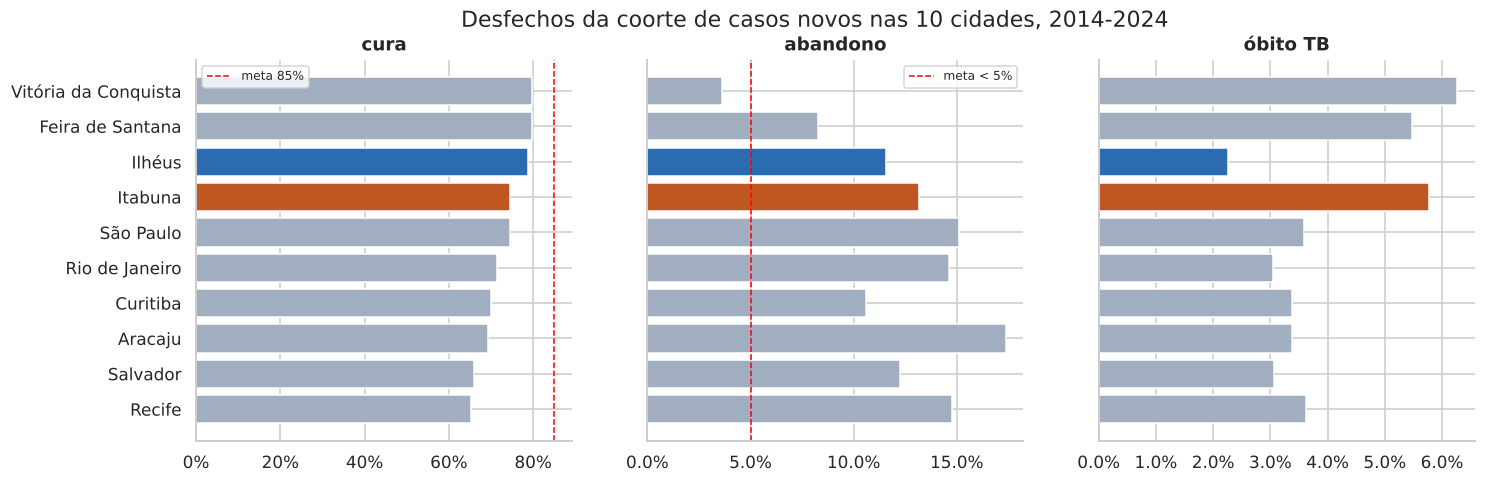

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, col in zip(axes, ['cura %', 'abandono %', 'óbito TB %']):
    s = tab10[col].sort_values()
    ax.barh(s.index, s.values, color=[cores.get(c, '#a0aec0') for c in s.index])
    ax.set_title(col.replace(' %', ''))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    if col == 'cura %':
        ax.axvline(85, color='red', ls='--', lw=1, label='meta 85%')
        ax.legend(fontsize=8)
    if col == 'abandono %':
        ax.axvline(5, color='red', ls='--', lw=1, label='meta < 5%')
        ax.legend(fontsize=8)
fig.suptitle('Desfechos da coorte de casos novos nas 10 cidades, 2014-2024')
tb.salva_fig(fig, '14_desfechos_10_cidades')
plt.show()

### Litoral x interior

Com só cinco cidades em cada grupo, a comparação é descritiva. Testamos a diferença das taxas somando casos e
populações de cada grupo (razão de taxas, Poisson).

In [8]:
from statsmodels.stats.rates import test_poisson_2indep
casos_cid['grupo'] = np.where(casos_cid['cidade'].isin(LITORAL), 'Litoral', 'Interior')
grp = casos_cid.groupby('grupo')[['casos', 'populacao']].sum()
grp['taxa /100 mil'] = grp['casos'] / grp['populacao'] * 1e5
r = test_poisson_2indep(grp.loc['Litoral', 'casos'], grp.loc['Litoral', 'populacao'],
                        grp.loc['Interior', 'casos'], grp.loc['Interior', 'populacao'])
print(f"Razão de taxas litoral/interior = {grp.loc['Litoral', 'taxa /100 mil'] / grp.loc['Interior', 'taxa /100 mil']:.2f}, p = {tb.fmt_p(r.pvalue)}")
print('Sem as capitais grandes (só as cidades baianas de médio porte):')
ba_medio = taxas10[taxas10['cidade'].isin(['Ilhéus', 'Itabuna', 'Vitória da Conquista', 'Feira de Santana'])]
display(ba_medio[['cidade', 'grupo', 'taxa média /100 mil', 'IC inf', 'IC sup']].round(1))
grp.round(1)

Razão de taxas litoral/interior = 1.74, p = <0,001
Sem as capitais grandes (só as cidades baianas de médio porte):


,cidade,grupo,taxa média /100 mil,IC inf,IC sup
2,Itabuna,Interior,70.5,67.0,74.2
4,Ilhéus,Litoral,58.6,55.3,62.1
7,Feira de Santana,Interior,28.7,27.4,30.0
9,Vitória da Conquista,Interior,17.4,16.1,18.7


,casos,populacao,taxa /100 mil
grupo,,,
Interior,76104,157483581.0,48.3
Litoral,101825,120943420.0,84.2


## 3. Bahia: incidência, IDH e densidade (A10)

Taxa média 2014-2024 em cada um dos 417 municípios. Em municípios pequenos a taxa oscila muito por acaso, então
repetimos a correlação só com municípios de 20 mil habitantes ou mais.

In [9]:
casos_ba = agreg[agreg['SG_UF'].eq('29')].groupby('ID_MN_RESI')['casos'].sum().rename('casos')
pop_ba = pop[pop['cod6'].str.startswith('29')].groupby('cod6')['populacao'].sum().rename('pessoa_anos')
ba = ind[ind['uf'].eq('BA')].set_index('cod6').join(casos_ba).join(pop_ba)
ba['casos'] = ba['casos'].fillna(0)
ba['taxa'] = ba['casos'] / ba['pessoa_anos'] * 1e5
ba['taxa_suavizada'] = (ba['casos'] + 1) / ba['pessoa_anos'] * 1e5
print(f"Municípios: {len(ba)}; taxa da Bahia = {ba['casos'].sum() / ba['pessoa_anos'].sum() * 1e5:.1f} por 100 mil")
ba['posicao'] = ba['taxa'].rank(ascending=False)
ba['posicao_20mil'] = ba.loc[ba['pop2022'] >= 20000, 'taxa'].rank(ascending=False)
ba.loc[[tb.COD_ILHEUS, tb.COD_ITABUNA, '293330', '291080', '292740'],
       ['nome', 'pop2022', 'casos', 'taxa', 'posicao', 'posicao_20mil', 'idhm_2010', 'densidade_2022']].round(1)

Municípios: 417; taxa da Bahia = 30.4 por 100 mil


,nome,pop2022,casos,taxa,posicao,posicao_20mil,idhm_2010,densidade_2022
cod6,,,,,,,,
291360,Ilhéus,178649.0,1161,58.6,5.0,3.0,0.7,112.4
291480,Itabuna,186708.0,1482,70.5,1.0,1.0,0.7,465.6
293330,Vitória da Conquista,370879.0,677,17.4,204.0,100.0,0.7,100.1
291080,Feira de Santana,616272.0,1895,28.7,80.0,36.0,0.7,472.6
292740,Salvador,2417678.0,16131,59.1,4.0,2.0,0.8,3483.7


In [10]:
print(f"Municípios com 20 mil habitantes ou mais: {int((ba['pop2022'] >= 20000).sum())}")
ba.loc[ba['pop2022'] >= 20000].sort_values('taxa', ascending=False)[['nome', 'pop2022', 'taxa', 'idhm_2010', 'densidade_2022']].head(15).round(1)

Municípios com 20 mil habitantes ou mais: 160


,nome,pop2022,taxa,idhm_2010,densidade_2022
cod6,,,,,
291480,Itabuna,186708.0,70.5,0.7,465.6
292740,Salvador,2417678.0,59.1,0.8,3483.7
291360,Ilhéus,178649.0,58.6,0.7,112.4
290560,Camacan,22579.0,54.3,0.6,38.6
291390,Ipiaú,40706.0,51.8,0.7,145.4
291490,Itacaré,27704.0,50.8,0.6,38.2
290690,Caravelas,20580.0,47.7,0.6,8.7
290340,Belmonte,20121.0,46.9,0.6,10.4
291072,Eunápolis,113710.0,44.5,0.7,79.7


In [11]:
corr = []
for rot, sub in [('Todos os municípios', ba), ('20 mil hab. ou mais', ba[ba['pop2022'] >= 20000])]:
    for var, nome in [('idhm_2010', 'IDH-M 2010'), ('densidade_2022', 'Densidade (hab/km²)')]:
        s = sub[[var, 'taxa']].dropna()
        rho, p = stats.spearmanr(s[var], s['taxa'])
        corr.append({'amostra': rot, 'variável': nome, 'n': len(s), 'rho de Spearman': rho, 'p': p})
corr = pd.DataFrame(corr)
corr.round(3)

,amostra,variável,n,rho de Spearman,p
0,Todos os municípios,IDH-M 2010,417,0.222,0.0
1,Todos os municípios,Densidade (hab/km²),417,0.336,0.0
2,20 mil hab. ou mais,IDH-M 2010,160,0.411,0.0
3,20 mil hab. ou mais,Densidade (hab/km²),160,0.429,0.0


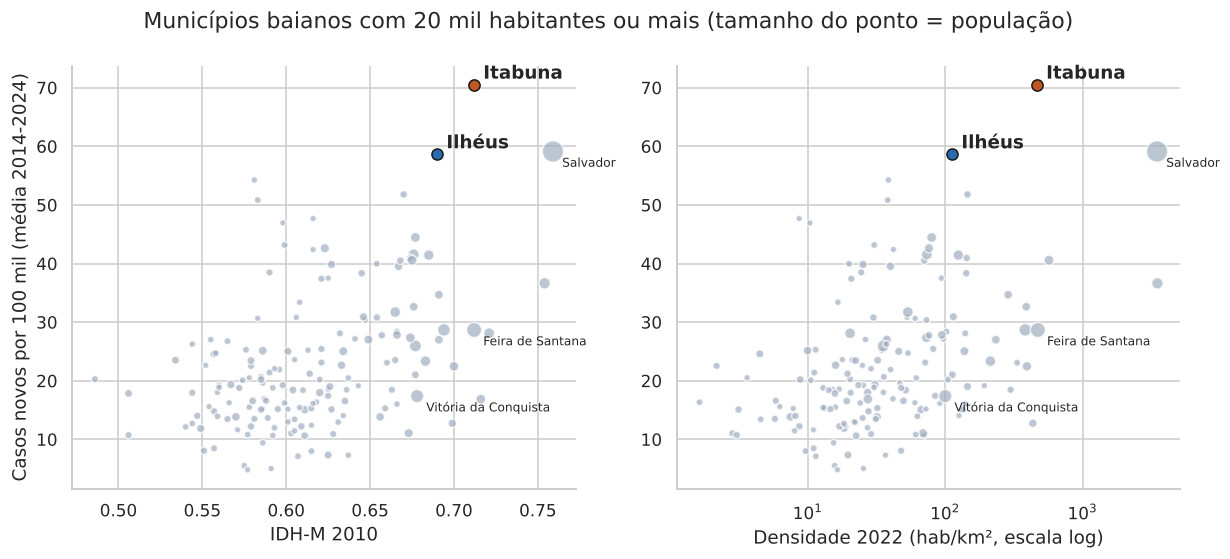

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sub = ba[ba['pop2022'] >= 20000]
for ax, var, rot, logx in [(axes[0], 'idhm_2010', 'IDH-M 2010', False), (axes[1], 'densidade_2022', 'Densidade 2022 (hab/km², escala log)', True)]:
    ax.scatter(sub[var], sub['taxa'], s=np.sqrt(sub['pop2022']) / 8, color='#a0aec0', alpha=0.7, edgecolor='white')
    for cod, c in [(tb.COD_ILHEUS, 'Ilhéus'), (tb.COD_ITABUNA, 'Itabuna')]:
        ax.scatter(sub.loc[cod, var], sub.loc[cod, 'taxa'], s=np.sqrt(sub.loc[cod, 'pop2022']) / 8, color=cores[c], edgecolor='k', zorder=3)
        ax.annotate(c, (sub.loc[cod, var], sub.loc[cod, 'taxa']), xytext=(6, 4), textcoords='offset points', fontweight='bold')
    for cod in ['292740', '291080', '293330']:
        ax.annotate(sub.loc[cod, 'nome'], (sub.loc[cod, var], sub.loc[cod, 'taxa']), xytext=(6, -10), textcoords='offset points', fontsize=8)
    if logx:
        ax.set_xscale('log')
    ax.set_xlabel(rot)
axes[0].set_ylabel('Casos novos por 100 mil (média 2014-2024)')
fig.suptitle('Municípios baianos com 20 mil habitantes ou mais (tamanho do ponto = população)')
tb.salva_fig(fig, '14_idh_densidade_incidencia')
plt.show()

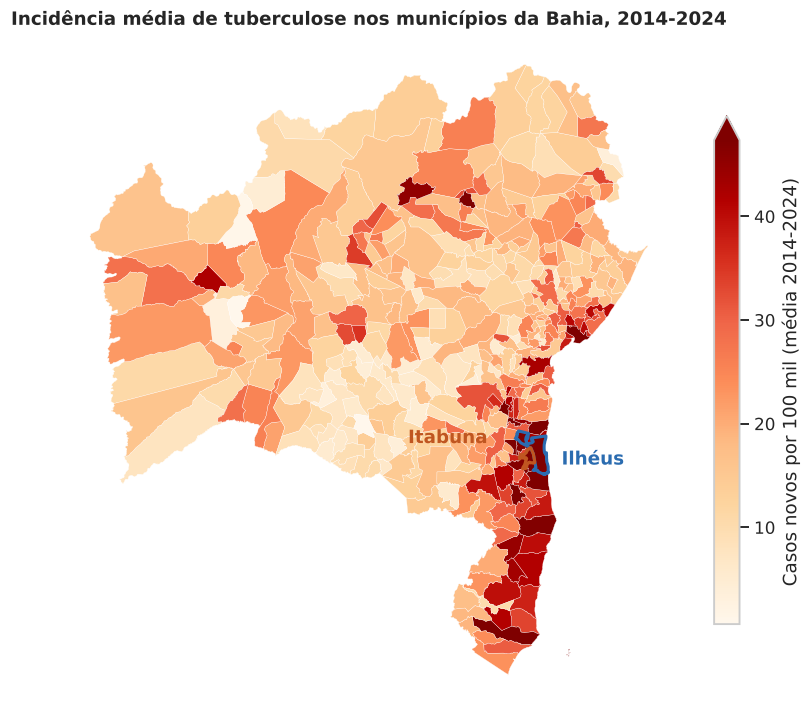

In [13]:
geo = gpd.read_file(tb.EXTERNAL / 'geojs-29-mun.json')
geo['cod6'] = geo['id'].astype(str).str[:6]
geo = geo.merge(ba[['taxa']], left_on='cod6', right_index=True, how='left')
fig, ax = plt.subplots(figsize=(9, 10))
geo.plot(column='taxa', cmap='OrRd', vmax=geo['taxa'].quantile(0.97), legend=True,
         legend_kwds={'label': 'Casos novos por 100 mil (média 2014-2024)', 'shrink': 0.6}, ax=ax, edgecolor='white', linewidth=0.2)
for cod, c in [(tb.COD_ILHEUS, 'Ilhéus'), (tb.COD_ITABUNA, 'Itabuna')]:
    g = geo[geo['cod6'] == cod]
    g.boundary.plot(ax=ax, color=cores[c], linewidth=2)
    pt = g.geometry.representative_point().iloc[0]
    ax.annotate(c, (pt.x, pt.y), xytext=(15, -8) if c == 'Ilhéus' else (-80, 10), textcoords='offset points', fontweight='bold', color=cores[c])
ax.set_axis_off()
ax.set_title('Incidência média de tuberculose nos municípios da Bahia, 2014-2024')
tb.salva_fig(fig, '14_mapa_bahia')
plt.show()

## 4. Pacientes de fora (A8)

Quantas notificações feitas em Ilhéus e em Itabuna são de pessoas que moram em outro município, de onde elas vêm,
como terminam o tratamento e quanto mudaria a incidência se contássemos por local de notificação.

In [14]:
notif = df[df['mun_not'].isin([tb.COD_ILHEUS, tb.COD_ITABUNA]) & df['ano_diag'].between(2014, 2024)].copy()
notif['cidade'] = notif['mun_not'].map(tb.CIDADES)
notif['origem'] = np.where(notif['mun_res'] == notif['mun_not'], 'Residente', 'De fora')
resumo_fora = notif.groupby('cidade').agg(notificacoes=('origem', 'size'),
                                          de_fora=('origem', lambda s: int(s.eq('De fora').sum())))
resumo_fora['% de fora'] = 100 * resumo_fora['de_fora'] / resumo_fora['notificacoes']
resumo_fora

,notificacoes,de_fora,% de fora
cidade,,,
Ilhéus,1629,173,10.620012
Itabuna,1802,68,3.773585


In [15]:
origens = (notif[notif['origem'] == 'De fora'].groupby(['cidade', 'nome_mun_res']).size()
           .rename('notificações').reset_index().sort_values(['cidade', 'notificações'], ascending=[True, False]))
origens.groupby('cidade').head(10).set_index(['cidade', 'nome_mun_res'])

notificações
cidade  nome_mun_res                     
Ilhéus  Uruçuca                        27
        Itacaré                        23
        Una                            20
        Itabuna                        15
        Canavieiras                    14
        Maraú                          10
        Camacan                         8
        Ubaitaba                        6
        Itapé                           4
        Buerarema                       3
Itabuna Ilhéus                         11
        Buerarema                       8
        São José da Vitória             8
        Itapé                           5
        Camamu                          3
        Canavieiras                     3
        Itapitanga                      3
        Pau Brasil                      3
        Coaraci                         2
        Eunápolis                       2

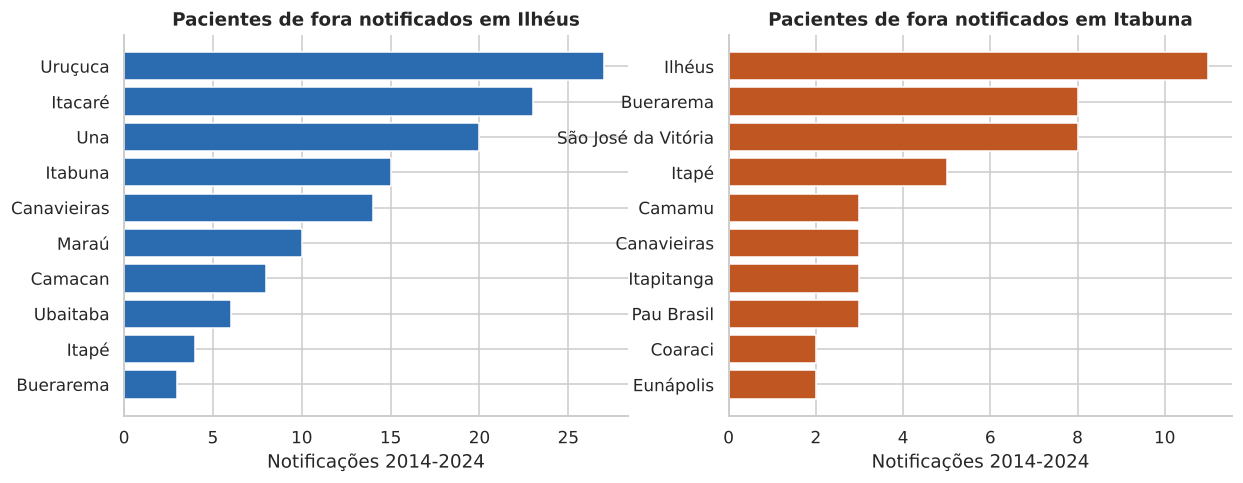

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, ['Ilhéus', 'Itabuna']):
    o = origens[origens['cidade'] == c].head(10).iloc[::-1]
    ax.barh(o['nome_mun_res'], o['notificações'], color=cores[c])
    ax.set_title(f'Pacientes de fora notificados em {c}')
    ax.set_xlabel('Notificações 2014-2024')
tb.salva_fig(fig, '14_origem_pacientes_fora')
plt.show()

In [17]:
# Desfechos de residentes x pacientes de fora (coorte de casos novos)
c_not = notif[notif['coorte_casos_novos'] & notif['desfecho'].ne('Sem encerramento')]
lin = []
for c in ['Ilhéus', 'Itabuna']:
    g = c_not[c_not['cidade'] == c]
    for ind_nome, col in [('cura', 'cura'), ('abandono', 'abandono'), ('óbito por TB', 'obito_tb'),
                          ('transferência', None)]:
        serie_ev = g['desfecho'].eq('Transferência').astype(int) if col is None else g[col].astype(int)
        a = serie_ev[g['origem'] == 'De fora']; b = serie_ev[g['origem'] == 'Residente']
        orr, lo, hi, p = tb.fisher_2x2(int(a.sum()), len(a) - int(a.sum()), int(b.sum()), len(b) - int(b.sum()))
        lin.append({'cidade': c, 'indicador': ind_nome, 'n de fora': len(a), '% de fora': 100 * a.mean(),
                    '% residentes': 100 * b.mean(), 'OR': orr, 'p': p})
fora_desf = pd.DataFrame(lin)
fora_desf['p Bonferroni'] = tb.bonferroni(fora_desf['p'])
fora_desf.round(3)

,cidade,indicador,n de fora,% de fora,% residentes,OR,p,p Bonferroni
0,Ilhéus,cura,118,64.407,79.063,0.479,0.001,0.005
1,Ilhéus,abandono,118,4.237,11.570,0.338,0.012,0.097
2,Ilhéus,óbito por TB,118,5.085,2.296,2.280,0.113,0.907
3,Ilhéus,transferência,118,16.949,2.755,7.204,0.000,0.000
4,Itabuna,cura,53,52.830,74.880,0.376,0.001,0.005
5,Itabuna,abandono,53,1.887,13.214,0.126,0.011,0.084
6,Itabuna,óbito por TB,53,20.755,5.643,4.379,0.000,0.002
7,Itabuna,transferência,53,11.321,2.684,4.628,0.004,0.032


In [18]:
# Incidência por residência x por notificação
lin = []
for c, cod in [('Ilhéus', tb.COD_ILHEUS), ('Itabuna', tb.COD_ITABUNA)]:
    p_tot = sum(tb.pop_cidade_ano(pop, cod, a) for a in tb.ANOS)
    n_res = int((df['mun_res'].eq(cod) & df['caso_novo'] & df['ano_diag'].between(2014, 2024)).sum())
    n_not = int((df['mun_not'].eq(cod) & df['caso_novo'] & df['ano_diag'].between(2014, 2024)).sum())
    lin.append({'cidade': c, 'casos novos por residência': n_res, 'casos novos por notificação': n_not,
                'taxa por residência': n_res / p_tot * 1e5, 'taxa por notificação': n_not / p_tot * 1e5,
                'diferença %': 100 * (n_not / n_res - 1)})
pd.DataFrame(lin).round(1)

,cidade,casos novos por residência,casos novos por notificação,taxa por residência,taxa por notificação,diferença %
0,Ilhéus,1161,1282,58.6,64.7,10.4
1,Itabuna,1482,1513,70.5,72.0,2.1


## 5. Quem atende os moradores de Ilhéus (A8)

Onde os residentes de Ilhéus são notificados e tratados, e em que tipo de unidade. Fazemos o mesmo para Itabuna,
para comparação.

In [19]:
res = tb.residentes_ii(df)
res['local_notificacao'] = np.where(res['mun_not'] == res['mun_res'], 'Na própria cidade', res['nome_mun_not'])
res['local_tratamento'] = np.where(res['mun_trat'].isna() | (res['mun_trat'] == res['mun_res']), 'Na própria cidade',
                                   res['mun_trat'].map(lambda c: ind.set_index('cod6')['nome'].get(c, c) if isinstance(c, str) else c))
for c in ['Ilhéus', 'Itabuna']:
    g = res[res['cidade'] == c]
    print(f'\n{c}: {len(g)} notificações de residentes')
    print('  notificados fora:', int((g['local_notificacao'] != 'Na própria cidade').sum()),
          f"({100 * (g['local_notificacao'] != 'Na própria cidade').mean():.1f}%)")
    print('  tratamento atual fora:', int((g['local_tratamento'] != 'Na própria cidade').sum()),
          f"({100 * (g['local_tratamento'] != 'Na própria cidade').mean():.1f}%)")
    print('  principais destinos de notificação:',
          g.loc[g['local_notificacao'] != 'Na própria cidade', 'local_notificacao'].value_counts().head(6).to_dict())


Ilhéus: 1489 notificações de residentes
  notificados fora: 33 (2.2%)
  tratamento atual fora: 31 (2.1%)
  principais destinos de notificação: {'Salvador': 11, 'Itabuna': 11, 'Barreiras': 5, 'Ipiaú': 2, 'Goiânia': 1, 'Vila Velha': 1}

Itabuna: 1762 notificações de residentes
  notificados fora: 28 (1.6%)
  tratamento atual fora: 33 (1.9%)
  principais destinos de notificação: {'Ilhéus': 15, 'Salvador': 8, 'Belo Horizonte': 2, 'Teixeira de Freitas': 1, 'Vitória da Conquista': 1, 'Senhor do Bonfim': 1}


In [20]:
tipo = pd.crosstab(res['cidade'], res['tipo_unidade'].fillna('Outros / não informado'), normalize='index') * 100
tipo = tipo[tipo.max().sort_values(ascending=False).index]
tipo.round(1)

tipo_unidade,Centro de saúde / UBS,Hospital geral,Outros / não informado,Hospital especializado,Central de gestão em saúde,Pronto atendimento (UPA),Unidade de apoio diagnose e terapia
cidade,,,,,,,
Ilhéus,77.8,12.4,9.1,0.5,0.0,0.1,0.0
Itabuna,82.8,7.8,8.5,0.6,0.2,0.2,0.1


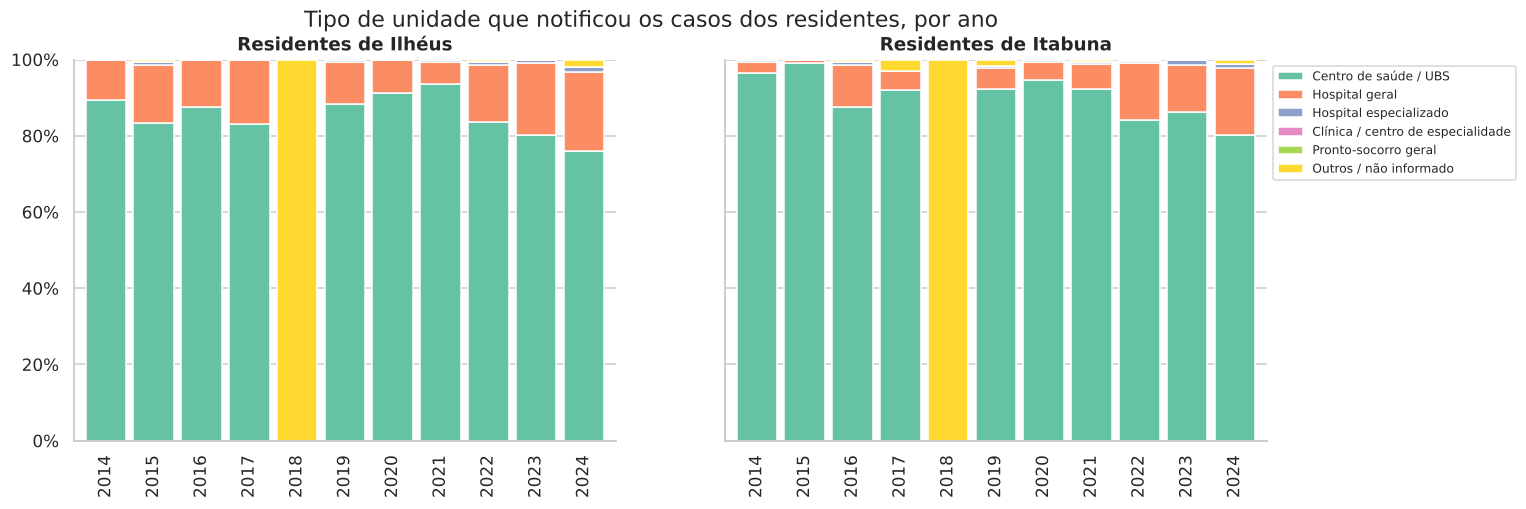

In [21]:
tipo_ano = (pd.crosstab([res['cidade'], res['ano_diag']], res['tipo_unidade'].fillna('Outros / não informado'), normalize='index') * 100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
cats = ['Centro de saúde / UBS', 'Hospital geral', 'Hospital especializado', 'Clínica / centro de especialidade', 'Pronto-socorro geral', 'Outros / não informado']
pal_t = sns.color_palette('Set2', len(cats))
for ax, c in zip(axes, ['Ilhéus', 'Itabuna']):
    t = tipo_ano.loc[c].reindex(columns=cats).fillna(0)
    outros = 100 - t.sum(axis=1)
    t['Outros / não informado'] = t['Outros / não informado'] + outros
    t.plot.bar(stacked=True, ax=ax, color=pal_t, width=0.85, legend=False)
    ax.set_title(f'Residentes de {c}')
    ax.set_xlabel('')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].legend(cats, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Tipo de unidade que notificou os casos dos residentes, por ano')
tb.salva_fig(fig, '14_tipo_unidade_residentes')
plt.show()

In [22]:
# Desfechos por tipo de unidade notificadora (coorte de casos novos dos residentes)
cr = res[res['coorte_casos_novos'] & res['desfecho'].ne('Sem encerramento')].copy()
cr['unidade'] = cr['tipo_unidade'].where(cr['tipo_unidade'].isin(['Centro de saúde / UBS', 'Hospital geral']), 'Outras')
cr.groupby(['cidade', 'unidade']).agg(n=('cura', 'size'), cura_pct=('cura', pct), abandono_pct=('abandono', pct),
                                     obito_tb_pct=('obito_tb', pct)).round(1)

n  cura_pct  abandono_pct  obito_tb_pct
cidade  unidade                                                          
Ilhéus  Centro de saúde / UBS   890      79.6          12.2           1.7
        Hospital geral          106      67.0           9.4           7.5
        Outras                  109      84.4           8.3           1.8
Itabuna Centro de saúde / UBS  1230      77.3          13.1           3.8
        Hospital geral          106      40.6          13.2          27.4
        Outras                  135      75.6          14.1           6.7

## 6. Comparação com números publicados (A11)

Comparamos os nossos números com boletins oficiais e com os dois estudos locais encontrados sobre Ilhéus. Não há
publicação com indicadores de Itabuna isolada; os boletins da Bahia trazem só a macrorregião Sul.
Diferenças pequenas são esperadas porque cada fonte extraiu o SINAN em uma data diferente e usa denominadores
próprios (por exemplo, cura de casos pulmonares confirmados no boletim x todos os casos novos aqui).

**Fontes**

- [SESAB, Boletim Epidemiológico TB, jan/2024](https://www.ba.gov.br/saude/sites/site-sesab/files/2026-09/Bol%20Epid%20TB%202024_0.pdf) — Tabela 2 (incidência 2014-2022) e Tabela 3 (testagem HIV por macrorregião).
- [SESAB, Boletim Epidemiológico TB nº 01, jul/2026](https://www.ba.gov.br/saude/sites/site-sesab/files/2026-09/BOLETIM%20EPID%20TB%202025--2026.pdf) — Tabela 01 (incidência 2023-2024, Bahia e macrorregião Sul) e cura da Bahia (p. 5).
- [Ministério da Saúde, Boletim Epidemiológico v. 56, nº 16, out/2025](https://www.gov.br/saude/pt-br/assuntos/saude-de-a-a-z/t/tuberculose/situacao-epidemiologica/boletim-epidemiologico-volume-56-no-16) — Brasil 2024.
- [Rodrigues et al., 2019, Varia Scientia 5(1)](https://e-revista.unioeste.br/index.php/variasaude/article/download/21577/14464/84284) — abandono em Ilhéus, 2014-2016 (CAE III, 46 de 447).
- [Medeiros, 2023, TCC Faculdade de Ilhéus](https://siga.faculdadedeilheus.com.br/ArquivosAnexos/PortalProfessor/Tcc/1/73f78fe5-a2eb-4377-94cf-43464ba5f5c7.pdf) — TB pulmonar em Ilhéus, 2018-2022.

In [23]:
inc_an = pd.read_csv(tb.PROCESSED / 'incidencia_anual.csv')
prog = pd.read_csv(tb.PROCESSED / 'indicadores_programa_ano.csv')
def taxa(local, ano):
    return float(inc_an.loc[inc_an['local'].eq(local) & inc_an['ano'].eq(ano), 'taxa'].iloc[0])

# Ilhéus por notificação, todas as entradas, para bater com os estudos locais
il_not = df[df['mun_not'].eq(tb.COD_ILHEUS)]
tcc = il_not[il_not['ano_diag'].between(2018, 2022) & il_not['pulmonar'].eq(True)]
rod = il_not[il_not['ano_diag'].between(2014, 2016)]
sul_hiv = lambda ano: prog[prog['ano_diag'].eq(ano)].set_index('cidade')['testagem HIV (%)']

pub = pd.DataFrame([
    ['Incidência Bahia 2014 (/100 mil)', 31.9, taxa('Bahia', 2014), 'SESAB jan/2024, Tab. 2'],
    ['Incidência Bahia 2019 (/100 mil)', 32.0, taxa('Bahia', 2019), 'SESAB jan/2024, Tab. 2'],
    ['Incidência Bahia 2020 (/100 mil)', 26.1, taxa('Bahia', 2020), 'SESAB jan/2024, Tab. 2'],
    ['Incidência Bahia 2022 (/100 mil)', 30.9, taxa('Bahia', 2022), 'SESAB jan/2024, Tab. 2'],
    ['Incidência Bahia 2023 (/100 mil)', 34.6, taxa('Bahia', 2023), 'SESAB jul/2026, Tab. 01'],
    ['Incidência Bahia 2024 (/100 mil)', 34.1, taxa('Bahia', 2024), 'SESAB jul/2026, Tab. 01'],
    ['Incidência macrorregião Sul 2023 x Ilhéus/Itabuna', 42.2, f"{taxa('Ilhéus', 2023):.1f} / {taxa('Itabuna', 2023):.1f}", 'SESAB jul/2026, Tab. 01'],
    ['Incidência macrorregião Sul 2024 x Ilhéus/Itabuna', 45.9, f"{taxa('Ilhéus', 2024):.1f} / {taxa('Itabuna', 2024):.1f}", 'SESAB jul/2026, Tab. 01'],
    ['Incidência Brasil 2024 (/100 mil)', 40.4, taxa('Brasil', 2024), 'MS BE v.56 nº 16'],
    ['Testagem HIV, macro Sul 2014 x Ilhéus/Itabuna (%)', 66.6, f"{sul_hiv(2014)['Ilhéus']:.1f} / {sul_hiv(2014)['Itabuna']:.1f}", 'SESAB jan/2024, Tab. 3'],
    ['Testagem HIV, macro Sul 2022 x Ilhéus/Itabuna (%)', 75.8, f"{sul_hiv(2022)['Ilhéus']:.1f} / {sul_hiv(2022)['Itabuna']:.1f}", 'SESAB jan/2024, Tab. 3'],
    ['Cura Bahia 2024 x Ilhéus/Itabuna (%)', 57.4, f"{prog.set_index(['cidade','ano_diag']).loc[('Ilhéus',2024),'cura (%)']:.1f} / {prog.set_index(['cidade','ano_diag']).loc[('Itabuna',2024),'cura (%)']:.1f}", 'SESAB jul/2026, p. 5'],
    ['Ilhéus 2014-2016: abandono (%)', round(100 * 46 / 447, 1), 100 * rod['abandono'].mean(), 'Rodrigues et al. 2019 (só CAE III)'],
    ['Ilhéus 2018-2022: casos de TB pulmonar', 661, len(tcc), 'Medeiros 2023 (TCC)'],
    ['Ilhéus 2018-2022 pulmonar: cura (%)', 60.96, 100 * tcc['cura'].mean(), 'Medeiros 2023 (TCC)'],
    ['Ilhéus 2018-2022 pulmonar: abandono (%)', 12.10, 100 * tcc['abandono'].mean(), 'Medeiros 2023 (TCC)'],
    ['Ilhéus 2018-2022 pulmonar: óbito por TB (%)', 2.11, 100 * tcc['obito_tb'].mean(), 'Medeiros 2023 (TCC)'],
    ['Ilhéus 2018-2022 pulmonar: HIV positivo (%)', 7.26, 100 * tcc['hiv'].eq('Positivo').mean(), 'Medeiros 2023 (TCC)'],
], columns=['indicador', 'publicado', 'esta análise', 'fonte'])
pub['esta análise'] = pub['esta análise'].map(lambda v: round(v, 1) if isinstance(v, float) else v)
pub

,indicador,publicado,esta análise,fonte
0,Incidência Bahia 2014 (/100 mil),31.90,33.2,"SESAB jan/2024, Tab. 2"
1,Incidência Bahia 2019 (/100 mil),32.00,32.0,"SESAB jan/2024, Tab. 2"
2,Incidência Bahia 2020 (/100 mil),26.10,25.8,"SESAB jan/2024, Tab. 2"
3,Incidência Bahia 2022 (/100 mil),30.90,30.3,"SESAB jan/2024, Tab. 2"
4,Incidência Bahia 2023 (/100 mil),34.60,30.2,"SESAB jul/2026, Tab. 01"
5,Incidência Bahia 2024 (/100 mil),34.10,31.0,"SESAB jul/2026, Tab. 01"
6,Incidência macrorregião Sul 2023 x Ilhéus/Itabuna,42.20,56.1 / 58.8,"SESAB jul/2026, Tab. 01"
7,Incidência macrorregião Sul 2024 x Ilhéus/Itabuna,45.90,67.5 / 75.6,"SESAB jul/2026, Tab. 01"
8,Incidência Brasil 2024 (/100 mil),40.40,41.2,MS BE v.56 nº 16
9,"Testagem HIV, macro Sul 2014 x Ilhéus/Itabuna (%)",66.60,52.1 / 79.4,"SESAB jan/2024, Tab. 3"


In [24]:
taxas10.to_csv(tb.PROCESSED / 'incidencia_10_cidades.csv', index=False)
tab10.to_csv(tb.PROCESSED / 'indicadores_10_cidades.csv')
ba[['nome', 'pop2022', 'casos', 'pessoa_anos', 'taxa', 'idhm_2010', 'densidade_2022']].to_csv(tb.PROCESSED / 'incidencia_municipios_bahia.csv')

## Conclusões

1. **Por 100 mil habitantes**, Itabuna (70,5) e Ilhéus (58,6) ficam no nível de Salvador (59,1) e São Paulo
   (54,6), abaixo apenas de Recife (97,3) e Rio de Janeiro (96,0). Feira de Santana (28,7) e Vitória da Conquista
   (17,4), cidades baianas de porte parecido, têm de 2 a 4 vezes menos.
2. **Desfechos.** Ilhéus tem mais cura (78,8% x 71,6%) e menos abandono (11,6% x 14,5%) do que as outras oito
   cidades somadas, ambos significativos após Bonferroni. Itabuna não difere em cura e abandono, mas tem mais óbito
   por TB (5,8% x 3,4%; OR 1,76). Nenhuma das 10 cidades chega a 85% de cura. A testagem para HIV de Ilhéus (63%) é
   a mais baixa das 10, e a proporção de privados de liberdade de Itabuna (17%) é a maior.
3. **Litoral x interior.** O litoral tem 1,7 vez a incidência do interior, mas o resultado é dominado por Rio e
   Recife contra São Paulo e Curitiba. Entre as quatro baianas, a divisão não se sustenta: Itabuna, que é do
   interior, tem a maior taxa. O que agrupa Ilhéus e Itabuna é a região sul, não a costa.
4. **Bahia.** Itabuna é o 1º e Ilhéus o 5º município em incidência média entre os 417 (3º entre os 160 com mais de
   20 mil habitantes). O mapa mostra uma faixa contínua de alta incidência no sul e extremo sul. IDH e densidade
   se correlacionam positivamente com a incidência (rho 0,41 e 0,43 nos municípios maiores): municípios mais
   urbanos e com mais serviço diagnosticam e concentram mais casos.
5. **Pacientes de fora.** 10,6% das notificações de Ilhéus são de moradores de outros municípios (Uruçuca, Itacaré,
   Una, Itabuna, Canavieiras); em Itabuna, 3,8%. Eles curam menos e são mais transferidos, e em Itabuna morrem mais
   (20,8% de óbito por TB, provavelmente casos graves internados). Contar por notificação aumentaria a incidência
   de Ilhéus em 10% e a de Itabuna em 2%; por isso usamos residência.
6. **Quem atende Ilhéus.** 98% dos moradores de Ilhéus são notificados e tratados na própria cidade (os demais em
   Salvador e Itabuna). 78% chegam pela UBS e 12% pelo hospital geral. Os notificados no hospital curam menos
   (67%) e morrem mais (7,5%). Em Itabuna o hospital geral concentra 27% de óbito por TB, um sinal de diagnóstico
   tardio.
7. **Números publicados.** As incidências da Bahia e do Brasil batem com os boletins até 2022 (diferenças de até
   1 ponto). Para 2023-2024 o boletim de 2026 dá valores maiores, provavelmente por usar uma extração mais recente do
   SINAN e outra população. Ilhéus e Itabuna ficam acima da macrorregião Sul (42 a 46 por 100 mil). Ilhéus testa
   menos para HIV que a média da macrorregião. O TCC sobre Ilhéus (2018-2022) bate com esta análise em casos, abandono,
   óbito e HIV positivo; a cura difere (61% x 70%), provavelmente pela forma de cálculo.